<a href="https://colab.research.google.com/github/rizzhabh06/SHAP-Banknote-Analysis/blob/main/SHAP_Banknote_Authentication_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install SHAP and the UCI dataset helper
!pip -q install shap ucimlrepo

In [ ]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import shap

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Fetch the UCI Banknote Authentication dataset
banknote = fetch_ucirepo(id=267)

X = banknote.data.features.copy()
y = banknote.data.targets.squeeze().copy()

print("Dataset shape:", X.shape)
print("\nFeatures:")
print(X.columns.tolist())
print("\nTarget values:")
print(sorted(y.unique()))
print("\nFirst 5 rows:")
display(X.head())

Dataset shape: (1372, 4)

Features:
['variance', 'skewness', 'curtosis', 'entropy']

Target values:
[np.int64(0), np.int64(1)]

First 5 rows:


,variance,skewness,curtosis,entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880


In [ ]:
# Basic dataset check
print("Missing values:")
print(X.isnull().sum())

print("\nClass distribution:")
print(y.value_counts())

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
dtype: int64

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


## 2. Split the data

We keep 80% for training and 20% for testing.

`random_state=42` makes the split reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1097
Testing samples: 275


## 3. Train the ML model

We use a **Random Forest Classifier**.

Random Forest is a collection of decision trees. Each tree makes a prediction and the forest combines their results.

We use 100 trees and keep the model simple.

In [ ]:
# Create and train the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


## 4. Evaluate the model

In [ ]:
# Make predictions on unseen test data
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9964

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       153
           1       0.99      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



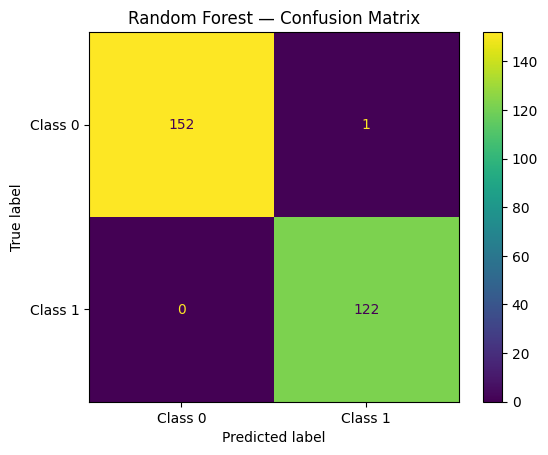

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot()
plt.title("Random Forest — Confusion Matrix")
plt.show()

## 5. Create the SHAP explainer

SHAP does **not** train the model.

The Random Forest has already been trained. SHAP now analyzes the trained model and estimates how much each feature contributes to its predictions.

Because Random Forest is a tree-based model, we use `TreeExplainer`.

In [ ]:
# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer(X_test)

print(shap_values.shape)

(275, 4, 2)


## 6. SHAP Bar Plot — Global Feature Importance

This summarizes the average absolute SHAP value of each feature.

A larger value means the feature has a larger average influence on the model's predictions.

**Important:** this is model importance, not proof that the feature causes the real-world outcome.

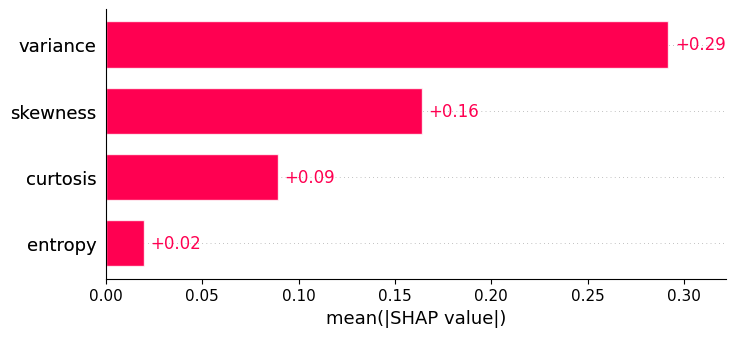

In [ ]:
# SHAP values for Class 1 (Forged)
shap_class1 = shap_values[:, :, 1]

# Global feature importance
shap.plots.bar(shap_class1, max_display=4)

Actual class: 1
Predicted class: 1

Feature values:


,variance,skewness,curtosis,entropy
899,-1.4446,2.1438,-0.47241,-1.6677


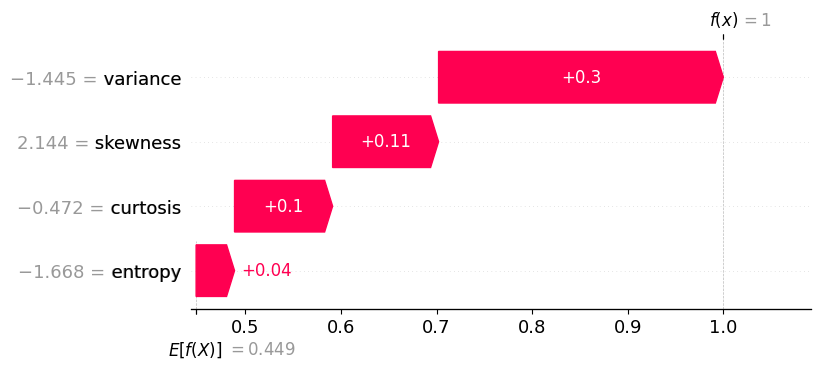

In [ ]:
# Find a correctly classified Class 1 sample
correct_class1 = [
    i for i in range(len(y_test))
    if y_test.iloc[i] == 1 and y_pred[i] == 1
]

sample_index = correct_class1[0]

print("Actual class:", y_test.iloc[sample_index])
print("Predicted class:", y_pred[sample_index])

print("\nFeature values:")
display(X_test.iloc[[sample_index]])

# Waterfall explanation for Class 1 (Forged)
shap.plots.waterfall(
    shap_class1[sample_index],
    max_display=4
)